In [1]:
# Logistic Regression

In [2]:
# 1. Import libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [4]:
# 2. Load dataset

In [5]:
df = pd.read_csv("bfsi_logistics_dataset.csv")

print(df.head())
print("\nShape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

        amount  frequency  location_score  fraud
0  2833.576524         19        0.611070      1
1  4685.608098         16        0.570374      1
2  3049.754513         12        0.745962      1
3  3209.426080         18        0.243608      1
4  3038.824137         19        0.731646      1

Shape: (10000, 4)

Missing values:
 amount            0
frequency         0
location_score    0
fraud             0
dtype: int64

Duplicates: 0


In [6]:
# 3. Check target distribution


Fraud distribution:
fraud
1    8876
0    1124
Name: count, dtype: int64


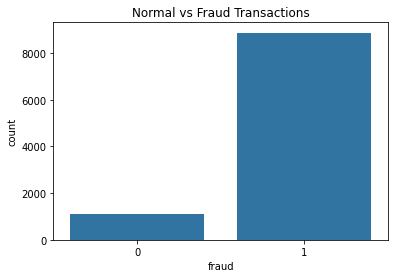

In [7]:
print("\nFraud distribution:")
print(df["fraud"].value_counts())

sns.countplot(data=df, x="fraud")
plt.title("Normal vs Fraud Transactions")
plt.show()

In [8]:
# 4. Define X and Y

In [9]:
X = df.drop("fraud", axis=1)
y = df["fraud"]

In [10]:
# 5. Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
# 6. Build Logistic Regression pipeline

In [13]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [14]:
# 7. Train model

In [15]:
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [16]:
# 8. Predictions

In [17]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [18]:
# 9. Evaluation

In [19]:
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9815
Precision: 1.0
Recall: 0.9791549295774647
F1 Score: 0.9894676914318247

Confusion Matrix:
[[ 225    0]
 [  37 1738]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92       225
           1       1.00      0.98      0.99      1775

    accuracy                           0.98      2000
   macro avg       0.93      0.99      0.96      2000
weighted avg       0.98      0.98      0.98      2000



In [20]:
# 10. Confusion matrix visualization

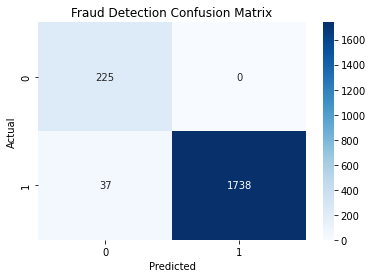

In [21]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection Confusion Matrix")
plt.show()

In [22]:
# 11. Predict a new transaction

In [23]:
new_transaction = pd.DataFrame({
    "amount": [5000],
    "frequency": [25],
    "location_score": [0.8]
})

prediction = model.predict(new_transaction)[0]
probability = model.predict_proba(new_transaction)[0][1]

print("\nFraud Prediction:", prediction)
print("Fraud Probability:", round(probability, 4))

if prediction == 1:
    print("Potentially Fraudulent Transaction")
else:
    print("Normal Transaction")


Fraud Prediction: 1
Fraud Probability: 1.0
Potentially Fraudulent Transaction


In [24]:
# Linear Regression

In [25]:
# 1. Import libraries

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [27]:
# 2. Load dataset

In [28]:
df = pd.read_csv("bfsi_regression_dataset.csv")

print(df.head())
print("\nShape:", df.shape)
print("\nDataset Information:")
print(df.info())

         income  credit_limit  txn_frequency         spend
0  29250.810247  17543.120644             24  46792.808965
1  49760.206810  18498.590717             29  44807.380291
2  56881.250972  23963.608190             15  61290.095565
3  50860.687702  16304.715063             18  39222.867023
4  43891.640345  14582.996443             17  39005.804117

Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   income         10000 non-null  float64
 1   credit_limit   10000 non-null  float64
 2   txn_frequency  10000 non-null  int64  
 3   spend          10000 non-null  float64
dtypes: float64(3), int64(1)
memory usage: 312.6 KB
None


In [29]:
# 3. Check data quality

In [33]:
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nStatistical summary:")
print(df.describe())


Missing values:
 income           0
credit_limit     0
txn_frequency    0
spend            0
dtype: int64

Duplicates: 0

Statistical summary:
              income  credit_limit  txn_frequency         spend
count   10000.000000  10000.000000   10000.000000  10000.000000
mean    50053.335170  19928.205083      20.006100  48967.353082
std     14874.482526   5013.287222       4.486544  10139.308299
min     -5119.095095   1962.142592       5.000000  11775.932609
25%     40019.367387  16601.688213      17.000000  42115.858147
50%     50125.008858  19942.054393      20.000000  48942.596072
75%     60130.632514  23233.431971      23.000000  55741.759445
max    103199.650524  38403.910866      40.000000  87473.978198


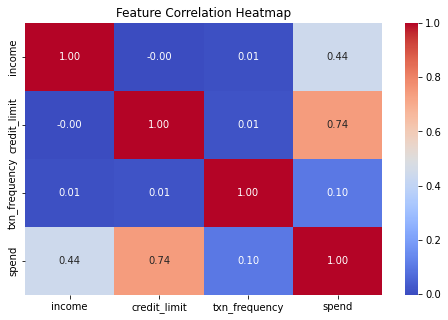

In [31]:
# 4. Exploratory Data Analysis
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [32]:
# 5. Define X and Y
X = df.drop("spend", axis=1)
y = df["spend"]

In [34]:
# 6. Train-test split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [36]:
# 7. Build Linear Regression model

In [37]:
model = LinearRegression()

In [38]:
# 8. Train model

In [39]:
model.fit(X_train, y_train)

LinearRegression()

In [40]:
# 9. Predict spending

In [41]:
y_pred = model.predict(X_test)

In [42]:
# 10. Compare actual and predicted values

In [43]:
results = pd.DataFrame({
    "Actual Spend": y_test.values,
    "Predicted Spend": y_pred
})

print("\nActual vs Predicted:")
print(results.head(10))


Actual vs Predicted:
   Actual Spend  Predicted Spend
0  50105.892776     52566.994514
1  46636.407308     47796.649754
2  62323.492820     59589.469590
3  44699.812495     44907.540924
4  38598.957442     39541.489596
5  50121.745495     52434.496042
6  48250.446095     47927.002048
7  51249.650992     52286.540119
8  43148.859706     46600.284555
9  42648.212489     44209.559675


In [44]:
# 11. Evaluate model

In [45]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("----------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation
----------------
MAE: 3947.0102420225585
MSE: 24597423.062542997
RMSE: 4959.578919882513
R2 Score: 0.7562038633871544


In [46]:
# 12. Actual vs Predicted visualization

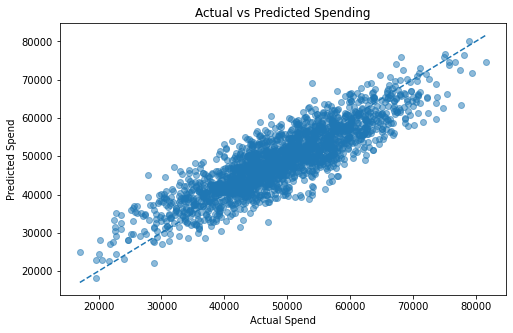

In [47]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Spend")
plt.ylabel("Predicted Spend")
plt.title("Actual vs Predicted Spending")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [48]:
# 13. Feature coefficient interpretation

In [49]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nFeature Coefficients:")
print(coefficients)

print("\nIntercept:", model.intercept_)


Feature Coefficients:
         Feature  Coefficient
0         income     0.302976
1   credit_limit     1.505707
2  txn_frequency   208.164045

Intercept: -364.5023461846213


In [50]:
# 14. Predict spending for a new customer

In [51]:
new_customer = pd.DataFrame({
    "income": [60000],
    "credit_limit": [25000],
    "txn_frequency": [22]
})

predicted_spend = model.predict(new_customer)

print("\nPredicted Monthly Spend:", round(predicted_spend[0], 2))


Predicted Monthly Spend: 60036.36
